In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

from itertools import product

import sys
from pathlib import Path

import time
from datetime import datetime

import warnings

In [2]:
def adaptive_prune_to_complete(
    data: pd.DataFrame,
    max_iter:int = 100,
    shrink_coeff:float = 10
):
    n_rows, n_cols = data.shape
    if n_rows == 0 or n_cols == 0:
        raise ValueError("Supplied matrix is degenerate")
    
    if shrink_coeff <= 0:
        raise ValueError("shrink_coeff must be positive")

    if shrink_coeff < 1:
        raise ValueError("shrink_coeff should be >= 1")

    if max_iter <= 0:
        raise ValueError("max_iter must be > 0")

    if not data.index.is_unique:
        raise ValueError("data index must be unique")

    if not data.columns.is_unique:
        raise ValueError("data columns must be unique")

    X = data.copy(deep=False)

    # container for benchmarking info
    # i: iteration no
    # no_pruned_cols: no of pruned columns
    # no_pruned_rows: no of pruned rows
    # eff_lr: effective learning rate
    iteration_info = []
    
    # iteration count
    i = 1
    while(i <= max_iter):
        ### remove columns ###

        # pick threshold
        # fraction of elements in the least populated column
        col_avail = X.notna().sum(axis=0)
        min_fraction_col = (col_avail/n_rows).min()
        # fraction of missing + shrunk learning_rate
        col_threshold = min_fraction_col + (1 - min_fraction_col)/(shrink_coeff * i)

        # save the number of old columns
        n_cols_old = X.shape[1]
        
        # prune columns
        X = X.loc[:, col_avail >= col_threshold * n_rows]
        
        # update column count
        n_cols = X.shape[1]
        # if all columns were pruned
        if n_cols == 0:
            iteration_info.append({
                "i": i,
                "no_pruned_rows": 0,
                "no_pruned_cols": n_cols_old - n_cols,
                "eff_lr": 1/(shrink_coeff * i)
            })
            iteration_info = pd.DataFrame(iteration_info)
            return None, None, iteration_info

        ### remove rows ###
        
        # pick threshold
        # fraction of elements in the least populated row
        row_avail = X.notna().sum(axis=1)
        min_fraction_row = (row_avail/n_cols).min()
        # fraction of missing + shrunk learning_rate
        row_threshold = min_fraction_row + (1 - min_fraction_row)/(shrink_coeff * i)

        n_rows_old = X.shape[0]
        
        # prune rows
        X = X.loc[row_avail >= row_threshold * n_cols, :]

        # update row count
        n_rows = X.shape[0]
        # if all rows were pruned
        if n_rows == 0:
            iteration_info.append({
                "i": i,
                "no_pruned_rows": n_rows_old - n_rows,
                "no_pruned_cols": n_cols_old - n_cols,
                "eff_lr": 1/(shrink_coeff * i)
            })
            iteration_info = pd.DataFrame(iteration_info)
            return None, None, iteration_info

        missing = X.isna().sum().sum()
        total = X.shape[0] * X.shape[1]

        iteration_info.append({
            "i": i,
            "no_pruned_rows": n_rows_old - n_rows,
            "no_pruned_cols": n_cols_old - n_cols,
            "eff_lr": 1/(shrink_coeff * i),
            "missing_no": missing,
            "missing_frac": missing/total
        })

        if missing == 0: break
        
        i += 1

    iteration_info = pd.DataFrame(iteration_info)
    if i <= max_iter: 
        return X.index.copy(), X.columns.copy(), iteration_info
    else:
        warnings.warn(
            f"{max_iter} iterations reached without convergence. "
            f"Remaining matrix has shape {X.shape} and {missing} missing values.",
            RuntimeWarning
        )
        return None, None, iteration_info

In [3]:
def extract_mask(matrix, excluded_rows, excluded_cols):
    excluded_mask = np.zeros(matrix.shape, dtype=bool)
    excluded_mask[np.ix_(excluded_rows, excluded_cols)] = True
    return ~excluded_mask

In [4]:
def apply_missingness(matrix, available_mask, missingness):
    # assumes applying missingness is possible
    no_missing = int(round(missingness * matrix.size))
    available_idx = np.flatnonzero(available_mask)

    missing_idx = rng.choice(available_idx, size = no_missing, replace = False)
    matrix.flat[missing_idx] = np.nan

In [5]:
def experiment(n_complete, d_complete, 
               n_big, d_big,
               missingness,
               C_list
              ):
    if n_complete > n_big or d_complete > d_big:
        raise ValueError("Complete matrix cannot be larger than the big matrix")
    
    # generate complete matrix to be planted
    complete = rng.standard_normal(size=(n_complete, d_complete))

    # generate big encompassing matrix
    big = rng.standard_normal((n_big, d_big))

    if big.size - complete.size < big.size * missingness:
        # print("Experiment not possible with given parameters")
        return None

    # plant a complete matrix
    rows = np.sort(rng.choice(n_big, size=n_complete, replace=False))
    cols = np.sort(rng.choice(d_big, size=d_complete, replace=False))
        
    big[np.ix_(rows,cols)] = complete

    # apply missingness
    available_mask = extract_mask(big, rows, cols)
    apply_missingness(big, available_mask, missingness)
        
    df = pd.DataFrame(big)

    # iteration information
    iter_info = {}

    results = []

    # go through all the Cs
    for C in C_list:
        # found submatrix, iteration information
        # or None, None, iteration info if failed
        start = time.perf_counter()
        found_rows, found_cols, iter_info[C] = adaptive_prune_to_complete(df, max_iter=1000, shrink_coeff=C)
        elapsed = time.perf_counter() - start

        if found_rows is not None and found_cols is not None:
            # check if a found matrix is indeed complete
            assert df.loc[found_rows, found_cols].isna().sum().sum() == 0, f"{C}"

            results.append({
                'C':C,
                'row_cnt': len(found_rows),
                'col_cnt': len(found_cols),
                'found_area': df.loc[found_rows, found_cols].size,
                'no_iter': iter_info[C]["i"].max(),
                'time_sec': elapsed
            })
        else:
            results.append({
                'C':C,
                'row_cnt': -1,
                'col_cnt': -1,
                'found_area': -1,
                'no_iter': iter_info[C]["i"].max(),
                'time_sec': elapsed
            })
    results = pd.DataFrame(results)
    
    return results

In [12]:
# experiment assessment helper
def distinct_solutions(matrices):
    ds = matrices[matrices["found_area"] > 0]
    ds = ds.sort_values(by=['row_cnt','col_cnt', 'C', 'time_sec'], ascending=[False, False, True, True])
    return ds.groupby(by='row_cnt', as_index=False).first()

In [13]:
# experiment assessment helper
def Pareto_frontier(matrices):
    ds = distinct_solutions(matrices)
    ds = ds.sort_values(by=['row_cnt', 'col_cnt'], ascending=[False, False])
    ds.reset_index(inplace=True)
    pf_idx = np.zeros(len(ds), dtype=bool)
    no_rows = 0
    no_cols = 0
    for solution in ds.itertuples():
        if (solution.row_cnt > no_rows) or (solution.col_cnt > no_cols):
            no_rows = solution.row_cnt
            no_cols = solution.col_cnt
            pf_idx[solution.Index] = True
    return ds.loc[pf_idx]

In [52]:
results_file = Path("../results/submatrix_planted_results_20260710_093819.txt").resolve()
results = pd.read_csv(results_file)

In [56]:
distinct_results = []

seeds = results["seed"].unique()
for seed in seeds:
    seed_mask = results["seed"] == seed
    distinct_results.append(distinct_solutions(results[seed_mask]))

distinct_results = pd.concat(distinct_results).reset_index()

# no of cases with no solution found
no_solutions_no = len(results['seed'].unique()) - len(distinct_results['seed'].unique())
print(f"No of matrices where no solution was found: {no_solutions_no}")

No of matrices where no solution was found: 1


In [84]:
distinct_results.head()

,index,row_cnt,big_rows,big_cols,complete_rows,complete_cols,missingness,C,seed,col_cnt,found_area,no_iter,time_sec
0,0,7,23,17,5,5,0.3,3,51,5,35,3,0.012408
1,1,8,23,17,5,5,0.3,4,51,6,48,7,0.019047
2,2,10,23,17,5,5,0.3,5,51,5,50,7,0.020280
3,0,4,23,17,5,5,0.5,5,52,7,28,6,0.014309
4,1,10,23,17,5,5,0.5,2,52,3,30,3,0.007722


In [104]:
largest_area_results = (
    distinct_results.loc[distinct_results.groupby(by='seed')['found_area'].idxmax(), 
        ['found_area', 'row_cnt', 'col_cnt', 'time_sec', 'C', 'complete_rows', 'complete_cols', 'missingness', 'big_rows', 'big_cols']
    ]
)
largest_area_results['excess'] = (
    largest_area_results['found_area'] / 
    (largest_area_results['complete_rows'] * largest_area_results['complete_cols']) - 1
)

In [105]:
# fraction of experiments arriving at better than planted solution
print(len(largest_area_results[largest_area_results['excess'] > 0])/len(largest_area_results))
# fraction of experiments arriving at at least as good as planted solution
print(len(largest_area_results[largest_area_results['excess'] >= 0])/len(largest_area_results))
# fraction of experiments arriving at at least 80% of planted area solution
print(len(largest_area_results[largest_area_results['excess'] >= -0.2])/len(largest_area_results))

0.3058823529411765
0.5411764705882353
0.6764705882352942


In [106]:
summary_by_missingness = (
    largest_area_results.groupby(by='missingness', as_index=False)
    .agg(
        n_experiments=('excess', 'size'),
        frac_g_planted=(
            'excess',
            lambda x: x.gt(0).mean()
        ),
        frac_ge_planted=(
            'excess',
            lambda x: x.ge(0).mean()
        ),
        frac_ge_08_planted=(
            'excess',
            lambda x: x.ge(-0.2).mean()
        ),
        frac_ge_05_planted=(
            'excess',
            lambda x: x.ge(-0.5).mean()
        ),
        mean_excess=('excess', 'mean'),
        median_excess=('excess', 'median'),
        min_excess=('excess', 'min'),
        max_excess=('excess', 'max'),
        p10_excess=('excess', lambda x: x.quantile(0.10)),
        p90_excess=('excess', lambda x: x.quantile(0.90))
    )
)
summary_by_missingness

,missingness,n_experiments,frac_g_planted,frac_ge_planted,frac_ge_08_planted,frac_ge_05_planted,mean_excess,median_excess,min_excess,max_excess,p10_excess,p90_excess
0,0.30,41,0.536585,0.682927,0.926829,1.000000,1.611045,0.285714,-0.363395,8.60,-0.146245,5.400000
1,0.50,39,0.461538,0.692308,0.769231,0.974359,0.433586,0.000000,-0.618037,2.64,-0.297143,1.868571
2,0.70,37,0.243243,0.513514,0.594595,0.810811,-0.035209,0.000000,-0.668701,1.28,-0.582886,0.600000
3,0.85,32,0.093750,0.437500,0.593750,0.750000,-0.208034,-0.100000,-0.770751,0.36,-0.602469,0.000000
4,0.95,21,0.000000,0.190476,0.285714,0.619048,-0.358609,-0.400000,-0.716049,0.00,-0.657143,0.000000


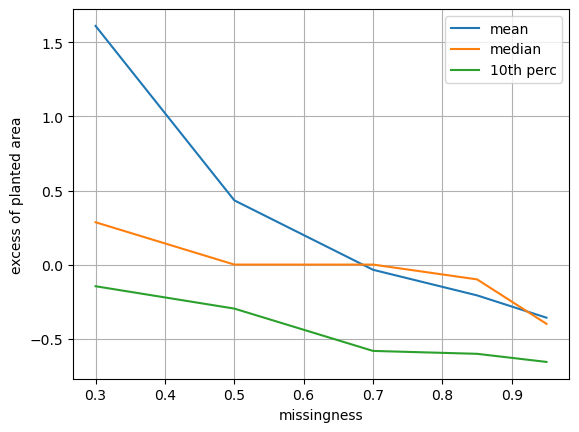

In [107]:
plt.plot(summary_by_missingness['missingness'], summary_by_missingness['mean_excess'], label='mean')
plt.plot(summary_by_missingness['missingness'], summary_by_missingness['median_excess'], label='median')
plt.plot(summary_by_missingness['missingness'], summary_by_missingness['p10_excess'], label='10th perc')
#plt.plot(summary_by_missingness['missingness'], summary_by_missingness['p90_excess'], label='90th perc')
plt.xlabel("missingness")
plt.ylabel("excess of planted area")
plt.grid(True)
plt.legend()
plt.show()

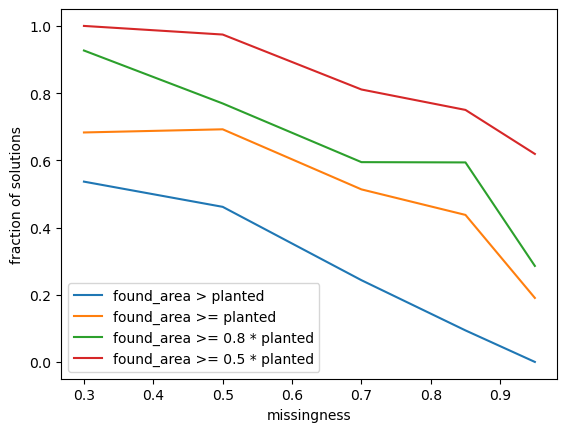

In [108]:
plt.plot(summary_by_missingness['missingness'], summary_by_missingness['frac_g_planted'], label='found_area > planted')
plt.plot(summary_by_missingness['missingness'], summary_by_missingness['frac_ge_planted'], label='found_area >= planted')
plt.plot(summary_by_missingness['missingness'], summary_by_missingness['frac_ge_08_planted'], label='found_area >= 0.8 * planted')
plt.plot(summary_by_missingness['missingness'], summary_by_missingness['frac_ge_05_planted'], label='found_area >= 0.5 * planted')
plt.xlabel("missingness")
plt.ylabel("fraction of solutions")
plt.legend()
plt.show()

In [109]:
largest_area_results['big_area'] = largest_area_results['big_rows'] * largest_area_results['big_cols']

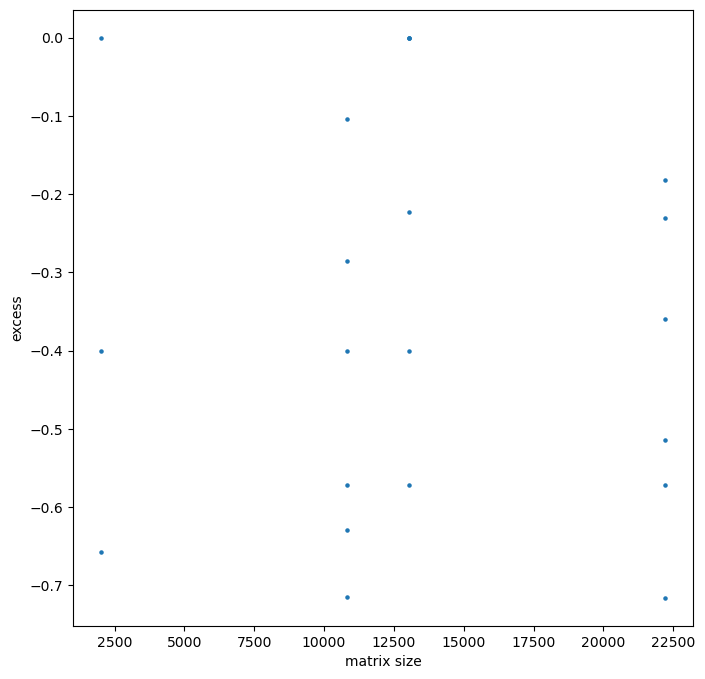

In [114]:
#mask = largest_area_results['excess'] < 3
#plot_df = largest_area_results[mask]
mask = largest_area_results['missingness'] == 0.95
plot_df = largest_area_results[mask]

fig, ax = plt.subplots(figsize=(8,8))
ax.scatter(plot_df['big_area'], plot_df['excess'], s=5)
ax.set_xlabel("matrix size")
ax.set_ylabel("excess")
plt.show()

In [9]:
# parameters to search through
#shs = np.arange(1, 10, 1)
shs = np.hstack((np.arange(1, 10), np.arange(10, 100, 10), np.arange(100, 500, 20)))

# no of dimensions to test
#D = 5

#low_complete_data_points = 5
#high_complete_data_points = 150
#no_complete_data_points = np.linspace(low_complete_data_points, high_complete_data_points, D).round().astype(int)

#low_complete_variables = 5
#high_complete_variables = 70
#no_complete_variables = np.linspace(low_complete_variables, high_complete_variables, D).round().astype(int)

#low_big_data_points = 10
#high_big_data_points = 200
#no_big_data_points = np.linspace(low_big_data_points, high_big_data_points, D).round().astype(int)

#low_big_variables = 7
#high_big_variables = 100
#no_big_variables = np.linspace(low_big_variables, high_big_variables, D).round().astype(int)

#complete_dims = list(product(no_complete_data_points, no_complete_variables))
#big_dims = list(product(no_big_data_points, no_big_variables))

big_dims = [
    (5, 5),          # tiny square sanity check

    (23, 17),        # small tall-ish
    (17, 29),        # small wide-ish
    (47, 43),        # small near-square

    (137, 79),       # medium tall
    (83, 157),       # medium wide
    (149, 149),      # medium square

    (503, 241),      # large tall
    (257, 509),      # large wide
    (487, 461),      # large near-square

    (1237, 719),     # very large tall
    (733, 1511),     # very large wide

    (2000, 3000),    # max benchmark
]

complete_dims = [
    (5, 5),          # tiny square

    (7, 5),          # small tall
    (5, 7),          # small wide
    (9, 9),          # small square

    (23, 11),        # medium-ish tall
    (13, 29),        # medium-ish wide
    (37, 31),        # medium-ish near-square

    (89, 47),        # large tall
    (53, 101),       # large wide
    (137, 137),      # large square

    (311, 173),      # very large tall
    (197, 389),      # very large wide
]

# missingness to test
missingness = [0.3, 0.5, 0.7, 0.85, 0.95]

results = []

T = 5

for b in range(len(big_dims)):
    for c in range(len(complete_dims)):
        # check if dimensions allow the smaller matrix to be planted inside the big one
        if (complete_dims[c][0] > big_dims[b][0]) or (complete_dims[c][1] > big_dims[b][1]):
            print("Not possible to plant a matrix")
            continue
        big_area = big_dims[b][0] * big_dims[b][1]
        planted_area = complete_dims[c][0] * complete_dims[c][1]
        for m in missingness:
            for t in range(T):
                matrices = experiment(complete_dims[c][0], complete_dims[c][1],
                                      big_dims[b][0], big_dims[b][1], 
                                      m,
                                      shs)
                # experiment was not possible with given dimensions and missingness
                if matrices is None:
                    continue
    
                ds = distinct_solutions(matrices)
                if ds.empty:
                    continue
    
                pf = Pareto_frontier(matrices)
                if pf.empty:
                    continue
                
                # largest area matrix
                pf = pf.sort_values(by=['found_area', 'row_cnt', 'col_cnt', 'C', 'time_sec'], ascending=[False, False, False, True, True])
                best_found_matrix = pf.iloc[0]
                best_found_area = best_found_matrix['found_area']
    
                # largest number of rows solution
                # excluding solutions with less than 2 columns
                mask = pf['col_cnt'] >= 2
                pf_more_2cols = pf[mask].sort_values(by=['row_cnt', 'col_cnt', 'C', 'time_sec'], ascending=[False, False, True, True])
                best_rows_matrix = pf_more_2cols.iloc[0] if not pf_more_2cols.empty else None
    
                # largest number of cols solution
                # excluding solutions with less than 3 rows
                mask = pf['row_cnt'] >= 3
                pf_more_3rows = pf[mask].sort_values(by=['col_cnt', 'row_cnt', 'C', 'time_sec'], ascending=[False, False, True, True])
                best_cols_matrix = pf_more_3rows.iloc[0] if not pf_more_3rows.empty else None
                
                results.append({
                    "big_area": big_area,
                    "big_rows": big_dims[b][0],
                    "big_cols": big_dims[b][1],
                    "planted_area": planted_area,
                    "pa_rows": complete_dims[c][0],
                    "pa_cols": complete_dims[c][1],
                    "missing": m,
                    "largest_area": best_found_area,
                    "la_rows": best_found_matrix['row_cnt'],
                    "la_cols": best_found_matrix['col_cnt'],
                    "la_C": best_found_matrix['C'],
                    "la_time": best_found_matrix['time_sec'],
                    # when better solution than planted is found excess > 0
                    # planted solution is 0
                    # worse solutions is < 0
                    "la_excess": best_found_area/planted_area - 1,
                    # number of distinct solutions
                    "no_distinct": len(ds),
                    "max_distinct_C": ds['C'].max(),
                    # no of Pareto frontier solutions
                    "no_pareto": len(pf),
                    "max_pareto_C": pf['C'].max(),
                    "best_row_rows": best_rows_matrix['row_cnt'] if best_rows_matrix is not None else np.nan,
                    "best_row_cols": best_rows_matrix['col_cnt'] if best_rows_matrix is not None else np.nan,
                    "best_row_C": best_rows_matrix['C'] if best_rows_matrix is not None else np.nan,
                    "best_col_rows": best_cols_matrix['row_cnt'] if best_cols_matrix is not None else np.nan,
                    "best_col_cols": best_cols_matrix['col_cnt'] if best_cols_matrix is not None else np.nan,
                    "best_col_C": best_cols_matrix['C'] if best_cols_matrix is not None else np.nan,
                })

results = pd.DataFrame(results)

timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
file_name = Path(f"../results/results_planted_{timestamp}.csv").resolve()
results.to_csv(file_name, index=False)

Not possible to plant a matrix
Not possible to plant a matrix
Not possible to plant a matrix
Not possible to plant a matrix
Not possible to plant a matrix
Not possible to plant a matrix
Not possible to plant a matrix
Not possible to plant a matrix
Not possible to plant a matrix
Not possible to plant a matrix
Not possible to plant a matrix


KeyboardInterrupt: 

In [15]:
np.max(big_dims[3])

np.int64(47)

# Exact benchmark

In [206]:
def read_matrix_solutions_from_file(matrix_file):
    with open(matrix_file) as mf:
        n_rows, n_cols = mf.readline().strip().split(" ")
        n_rows  = int(n_rows)
        n_cols = int(n_cols)
    
        matrix = np.empty((n_rows, n_cols), dtype = float)
        
        # read a matrix
        for i in range(n_rows):
            row = mf.readline().strip()
            matrix[i, :] = (np.frombuffer(row.encode('ascii'), dtype = np.uint8) == ord(b'1'))
        #the \n
        mf.readline()

        solutions = mf.readlines()
        solutions = np.array([line.strip().split() for line in solutions], dtype = 'uint32')
    return matrix, solutions

In [201]:
BENCHMARK_MATRICES_FOLDER = Path("../results/benchmark_matrices/").resolve()

In [ ]:
#TODO add matrix size
#TODO add execution time

In [243]:
results = []

lrs = np.logspace(-3, 0, 10)
shs = np.arange(2, 101, 10)

for matrix_file in BENCHMARK_MATRICES_FOLDER.iterdir():
    matrix, solutions = read_matrix_solutions_from_file(matrix_file)
    
    missingness = df_matrix.isna().sum().sum()/df_matrix.size
    if missingness == 1: continue

    if len(solutions) == 0: continue
    
    area = solutions[0][0].bit_count() * solutions[0][1].bit_count()
    
    df_matrix = pd.DataFrame(matrix)
    df_matrix[df_matrix == 0] = np.nan
    
    best_submatrix_area = 0
    areas_ratio = 0
    
    for lr in lrs:
        for sh in shs:
            submatrix = adaptive_prune_to_complete(df_matrix, learning_rate=lr, shrink_coeff=sh, verbose = False)
            if submatrix is None: continue
            submatrix_area = submatrix.size
            if best_submatrix_area < submatrix_area:
                best_submatrix_area = submatrix_area
                areas_ratio = best_submatrix_area / area
            if submatrix_area == area:
                for solution in solutions:
                    row_mask = int(solution[0])
                    row_indices = pd.Index([i for i in range(row_mask.bit_length()) if row_mask & (1 << i)])
                    if row_indices.equals(submatrix.index):
                        col_mask = int(solution[1])
                        col_indices = pd.Index([i for i in range(col_mask.bit_length()) if col_mask & (1 << i)])
                        if (col_indices == submatrix.columns).all():
                            pass
    results.append({
        "file": matrix_file.name,
        "matrix_area": matrix.size,
        "missing": missingness,
        "optimal_area": area,
        "submatrix_area": area,
        "areas_ratio": areas_ratio,
    })

results = pd.DataFrame(results)

In [238]:
results = results.assign(opt_to_matrix=lambda x:x.optimal_area / x.matrix_area)
ratio_bins = np.arange(0, 1.1, 0.1)
results["ratio_bucket"] = pd.cut(results["opt_to_matrix"], bins=ratio_bins, include_lowest=True, right=False)
results_across_solution_to_matrix_ratio = (
    results
    .assign(recovered_90=results["areas_ratio"] >= 0.9)
    .groupby("ratio_bucket", observed=True)
    .agg(
        n=("areas_ratio", "size"),
        mean_recovery=("areas_ratio", "mean"),
        median_recovery=("areas_ratio", "median"),
        optimal_rate=("areas_ratio", lambda x: (x == 1).mean()),
        recovery_90_rate=("recovered_90", "mean"),
    )
)
results_across_solution_to_matrix_ratio

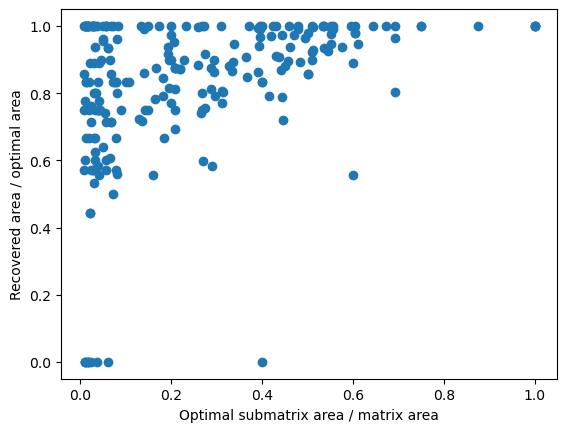

In [242]:
plt.scatter(
    results["optimal_area"] / results["matrix_area"],
    results["areas_ratio"]
)

plt.xlabel("Fraction of matrix area occupied by the optimal solution")
plt.ylabel("Recovered fraction of optimal area")
plt.show()

In [219]:
bins = np.arange(0, 1.1, 0.1)
results["missing_bucket"] = pd.cut(results["missing"], bins=bins, include_lowest = True, right = False)

In [222]:
results_across_missingness = (
    results
    .assign(recovered_90=results["areas_ratio"] >= 0.9)
    .groupby("missing_bucket", observed=True)
    .agg(
        n=("areas_ratio", "size"),
        mean_recovery=("areas_ratio", "mean"),
        median_recovery=("areas_ratio", "median"),
        optimal_rate=("areas_ratio", lambda x: (x == 1).mean()),
        recovery_90_rate=("recovered_90", "mean"),
    )
)
results_across_missingness

,n,mean_recovery,median_recovery,optimal_rate,recovery_90_rate
missing_bucket,,,,,
"[0.0, 0.1)",57,0.802655,0.875000,0.228070,0.438596
"[0.1, 0.2)",42,0.816150,0.888889,0.309524,0.452381
"[0.2, 0.3)",18,0.826761,0.870536,0.222222,0.444444
"[0.3, 0.4)",1,1.000000,1.000000,1.000000,1.000000
"[0.4, 0.5)",21,0.883952,0.946746,0.380952,0.619048
"[0.5, 0.6)",18,0.876317,0.899038,0.222222,0.500000
"[0.6, 0.7)",20,0.902649,0.927083,0.400000,0.600000
"[0.7, 0.8)",17,0.746206,0.833333,0.058824,0.352941
"[0.8, 0.9)",15,0.836862,0.897436,0.133333,0.400000


In [229]:
size_bins = np.arange(0, 900, 10)
size_bins
pd.cut(results["matrix_area"], bins=size_bins, include_lowest = True, right = False)

0      [500, 510)
1      [300, 310)
2      [300, 310)
3      [860, 870)
4      [300, 310)
          ...    
226    [300, 310)
227    [300, 310)
228    [300, 310)
229    [500, 510)
230    [500, 510)
Name: matrix_area, Length: 231, dtype: category
Categories (89, interval[int64, left]): [[0, 10) < [10, 20) < [20, 30) < [30, 40) ... [850, 860) < [860, 870) < [870, 880) < [880, 890)]

In [230]:
size_bins = np.arange(0, 900, 10)
results["size_bucket"] = pd.cut(results["matrix_area"], bins=size_bins, include_lowest = True, right = False)

In [231]:
results_across_size = (
    results
    .assign(recovered_90=results["areas_ratio"] >= 0.9)
    .groupby("size_bucket", observed=True)
    .agg(
        n=("areas_ratio", "size"),
        mean_recovery=("areas_ratio", "mean"),
        median_recovery=("areas_ratio", "median"),
        optimal_rate=("areas_ratio", lambda x: (x == 1).mean()),
        recovery_90_rate=("recovered_90", "mean"),
    )
)
results_across_size

,n,mean_recovery,median_recovery,optimal_rate,recovery_90_rate
size_bucket,,,,,
"[10, 20)",16,0.876736,1.000000,0.687500,0.687500
"[50, 60)",18,0.822584,0.895238,0.444444,0.500000
"[80, 90)",18,0.886070,0.989796,0.500000,0.722222
"[180, 190)",24,0.849703,0.958838,0.375000,0.541667
"[300, 310)",60,0.823434,0.884444,0.200000,0.466667
"[500, 510)",60,0.799397,0.870753,0.116667,0.400000
"[860, 870)",35,0.798224,0.800000,0.057143,0.228571


In [ ]:
#TODO results for optimal_area/matrix_size

,n,mean_recovery,median_recovery,optimal_rate,recovery_90_rate
missing_bucket,,,,,
"[0.0, 0.1)",57,0.802655,0.875000,0.228070,0.438596
"[0.1, 0.2)",42,0.816150,0.888889,0.309524,0.452381
"[0.2, 0.3)",18,0.826761,0.870536,0.222222,0.444444
"[0.3, 0.4)",1,1.000000,1.000000,1.000000,1.000000
"[0.4, 0.5)",21,0.883952,0.946746,0.380952,0.619048
"[0.5, 0.6)",18,0.876317,0.899038,0.222222,0.500000
"[0.6, 0.7)",20,0.902649,0.927083,0.400000,0.600000
"[0.7, 0.8)",17,0.746206,0.833333,0.058824,0.352941
"[0.8, 0.9)",15,0.836862,0.897436,0.133333,0.400000


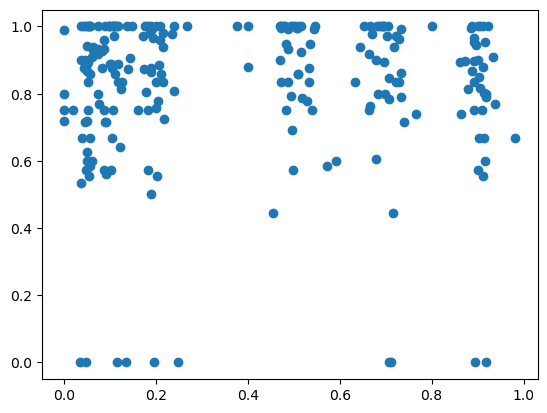

In [213]:
import matplotlib.pyplot as plt

plt.scatter(results["missing"], results["areas_ratio"])
plt.show()

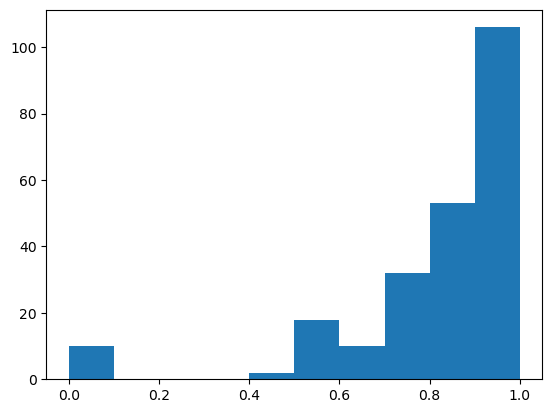

In [216]:
plt.hist(results["areas_ratio"])
plt.show()

In [215]:
missing_mask = ((results["missing"] >= 0) & (results["missing"] <= 0.5))
results_100_ratio_mask = results["areas_ratio"] == 1
results_90_ratio_mask = results["areas_ratio"] >= 0.9
print((missing_mask & results_100_ratio_mask).sum() / len(results[missing_mask]))
print((missing_mask & results_90_ratio_mask).sum() / len(results[missing_mask]))

0.2785714285714286
0.4714285714285714
